In [1]:
import numpy as np
import sacc
import matplotlib.pyplot as plt
import pyccl as ccl
import mfcs
import healpy as hp

In [2]:
planck_names = ['Planck__NPIPEnu100', 'Planck__NPIPEnu143', 'Planck__NPIPEnu217',
                'Planck__NPIPEnu353', 'Planck__NPIPEnu545', 'Planck__NPIPEnu857']
wl_names = [f'KiDS1000__{i}' for i in range(5)]
namefreq = {pn: pn.split("nu")[-1] for pn in planck_names}

# Read (and fix) SACC file


In [3]:
s = sacc.Sacc.load_fits('../cls_KiDS_Planck.fits')

# We just need to fix the sacc file to add missing beams
fwhm = {
    "Planck__NPIPEnu030": 32.29,
    "Planck__NPIPEnu044": 27.94,
    "Planck__NPIPEnu070": 13.08,
    "Planck__NPIPEnu100": 9.66,
    "Planck__NPIPEnu143": 7.22,
    "Planck__NPIPEnu217": 4.90,
    "Planck__NPIPEnu353": 4.92,
    "Planck__NPIPEnu545": 4.67,
    "Planck__NPIPEnu857": 4.22,
}
nside = 2048
pixwin = hp.pixwin(nside, lmax=3*nside-1)
for pn in planck_names:
    beam = hp.gauss_beam(fwhm=np.deg2rad(fwhm[pn] / 60.0), lmax=3*nside-1)
    s.tracers[pn].beam = beam*pixwin

# Read bandpass data
In principle these could (should) be stored in the sacc file.

In [4]:
bandpasses = {pn: mfcs.BPass(fname=f"data/planck_bandpass/HFI_BANDPASS_F{namefreq[pn]}_reformat.txt" if int(namefreq[pn]) >= 100 else f"data/planck_bandpass/LFI_BANDPASS_F{namefreq[pn]}_reformat.txt") for pn in planck_names}

# Create SED dictionary for CIB and tSZ

In [5]:
# SED dictionary for the CIB
cosmo = ccl.CosmologyVanillaLCDM()
sed_u_file = "data/SIDES_SED/SED_U_finegrids.save"
bm = mfcs.SIDESBethermin(sed_u_file)
# Color correction to be implemented
color_corr = {
    "Planck__NPIPEnu100": 1.076,
    "Planck__NPIPEnu143": 1.017,
    "Planck__NPIPEnu217": 1.119,
    "Planck__NPIPEnu353": 1.097,
    "Planck__NPIPEnu545": 1.068,
    "Planck__NPIPEnu857": 0.995,
}
# SIDEs physical parameters
sides_params = {
    "logU_ms_int": 0.31,
    "logU_ms_slope": 0.69,
    "logU_sb_int": -0.25,
    "logU_sb_slope": 1.63,
    "sb_frac_at_z0": 0.015,
    "sb_frac_at_zsat": 0.030,
    "sb_zsat": 1.0,
    "Ums_zsat": 4.0,
    }
cib_sed_dict = {}
for wln in wl_names:
    cib_sed_dict[wln] = {}
    # WL kernel to average over
    tr = ccl.WeakLensingTracer(cosmo, dndz=(s.tracers[wln].z, s.tracers[wln].nz))
    W, chi = np.array(tr.get_kernel()).squeeze()
    z = 1/ccl.scale_factor_of_chi(cosmo, chi)-1
    # Add an offset so the first element of z is not exactly
    # zero (problematic when calculating fluxes)
    z[0] += 0.00001
    # SED function before convolving with bandpasses
    sed = lambda nu: bm.sed_avgz(nu, z, W*chi**2, cosmo, **sides_params)
    # Convolve with all bandpasses
    for pn in planck_names:
        bb = bandpasses[pn]
        cib_sed_dict[wln][pn] = bb.convolve(sed, fast=True)*color_corr[pn]

# Create SED dictionary for tSZ
# Note that this one need only be defined for the Planck frequencies, since
# the SED is redshift-independent.
tsz_sed_dict = {pn: bandpasses[pn].convolve(mfcs.tSZ_sed) for pn in planck_names}

# SED dictionary for all components
seds = {'tSZ': tsz_sed_dict, 'CIB': cib_sed_dict}

# Precompute component separation matrices

In [6]:
lmaxs = {pn: 2*nside for pn in planck_names}
lmaxs['Planck__NPIPEnu857'] = 300
c = mfcs.MaxLikeBandpowerReconstructor(
    s, lss_names=wl_names, map_names=planck_names,
    comp_names=['tSZ', 'CIB'], seds=seds,
    maps_in_x='all', lmax=lmaxs, lmin=30,
    lss_spin=2, beam_correction_kind='bpw')

# Obtain MLBR solution

In [7]:
cls_comp_mlbr, cov_comp_mlbr = c.get_component_cls(get_cov=True)

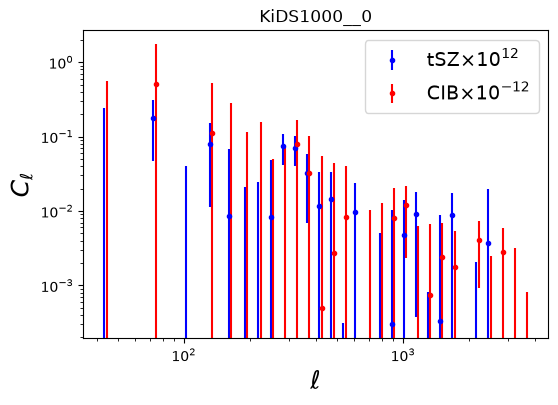

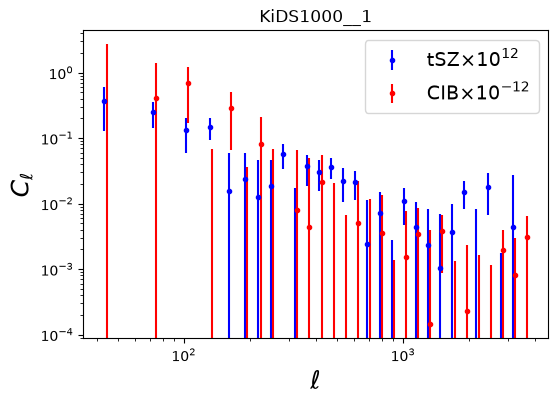

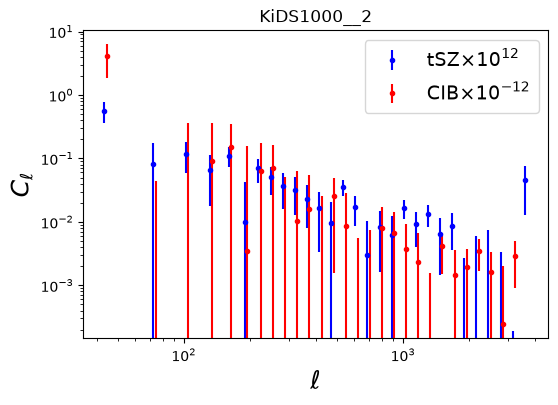

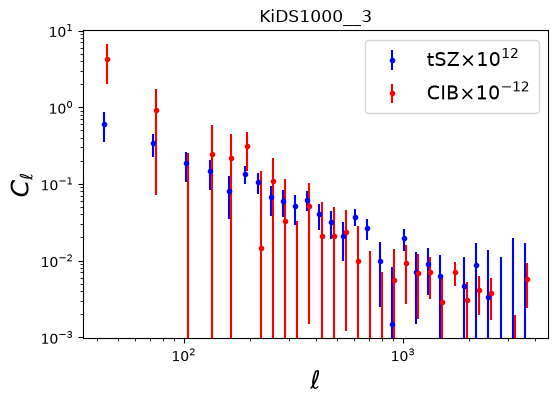

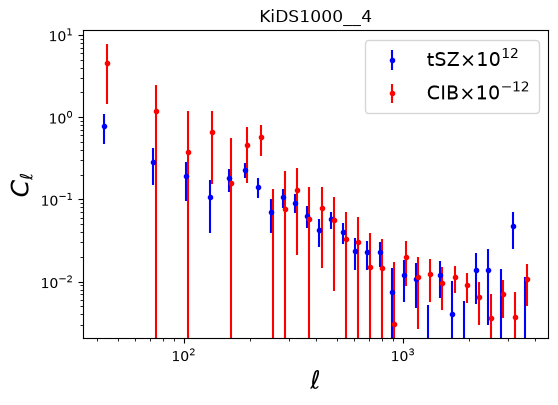

In [8]:
for iwl, wl in  enumerate(wl_names):
    plt.figure(figsize=(6, 4))
    plt.title(wl)
    for icomp, (comp, lpref) in enumerate(zip(['tSZ', 'CIB'], [12, -12])):
        ind = c.get_component_indices(wl, comp)
        cl = cls_comp_mlbr[ind]
        cov = cov_comp_mlbr[ind][:, ind]
        ls = c.common_ells[wl]
        pref = 10**lpref
        plt.errorbar(ls*(1-0.025+0.025*icomp), pref*cl, yerr=pref*np.sqrt(np.diag(cov)),
                     fmt=['b', 'r'][icomp]+'.', label=comp+f'$\\times 10^{{{lpref}}}$')
    plt.xlabel(r'$\ell$', fontsize=18)
    plt.ylabel(r'$C_\ell$', fontsize=18)
    plt.loglog()
    plt.legend(fontsize=14)